# snow Tutorial 6 - Broadband SHG and Dispersion Engineering

In Tutorial 5 a 100 fs pump was doubled in a waveguide whose group-velocity mismatch (GVM) between 2 µm and 1 µm is 13 fs/mm. Here we use a shorter, 30 fs pump and compare that waveguide with one whose geometry was chosen for zero GVM. The comparison shows what limits the bandwidth of SHG and what dispersion engineering buys.

We start with the usual imports and definitions.

In [1]:
import numpy as np
from numpy.fft import fft, ifft, fftshift, fftfreq
import matplotlib.pyplot as plt

import os, sys
sys.path.insert(0, os.path.abspath('..'))  # use this repo's snow package
import snow.pulses as pulses
import snow.materials as materials
import snow.waveguides as waveguides

from scipy.constants import pi, c, epsilon_0
nm = 1e-9
um = 1e-6
mm = 1e-3
ps = 1e-12
fs = 1e-15
MHz = 1e6
GHz = 1e9
THz = 1e12
pJ = 1e-12
fJ = 1e-15
mW = 1e-3
uW = 1e-6

#Larger font for plots
plt.rcParams.update({'font.size': 14})

## Theory: the phase-matching bandwidth

For a pump at $\omega + \delta$, the SHG phase mismatch is $\Delta k(\delta) = \beta(2\omega + 2\delta) - 2\beta(\omega + \delta)$. Expanding around the phase-matched $\omega$, where the grating cancels $\Delta k(0)$:

$$
\Delta k(\delta) - K_g \approx 2\,(\beta_{1,\mathrm{SH}} - \beta_{1,\mathrm{p}})\,\delta + (2\beta_{2,\mathrm{SH}} - \beta_{2,\mathrm{p}})\,\delta^2 + \dots
$$

The efficiency falls as $\mathrm{sinc}^2(\Delta k' L/2)$, which drops to one half at $|\Delta k'| L/2 = 1.39$. So:

- **With GVM**, the linear term dominates and the full width at half maximum (in pump angular frequency) is
  $\Delta\omega_\mathrm{FWHM} = \dfrac{2.78}{|\Delta\beta_1|\,L}$, which shrinks as $1/L$.
- **At zero GVM**, the quadratic term takes over: $\Delta\omega_\mathrm{FWHM} = 2\sqrt{\dfrac{2.78}{|2\beta_{2,\mathrm{SH}} - \beta_{2,\mathrm{p}}|\,L}}$, which shrinks only as $1/\sqrt{L}$.

In the time domain the same physics is the walk-off: pump and SH separate over $L_w = \tau/|\Delta\beta_1|$. Past $L_w$ the SH stops growing as $L^2$ and its spectrum narrows. At zero GVM the pulses stay together, and only the GVD of each pulse limits the interaction.

## Two waveguides

Waveguide A is the one from Tutorials 4 and 5. For waveguide B we keep the 700 nm film, etch 400 nm, and solve for the width that gives zero GVM. The GVM map in Tutorial 4 shows where that contour lies.

In [2]:
from scipy.optimize import brentq

λp = 2*um
hLN = 700*nm
X0 = 1.1e-12

def gvm(w, h_etch):
    wg = waveguides.Waveguide(waveguides.RidgeIndex(w_top=w, h_thinfilm=hLN, h_etch=h_etch))
    return wg.beta1(λp/2) - wg.beta1(λp)

etch_B = 400*nm
width_B = brentq(gvm, 1.5*um, 2.0*um, args=(etch_B,), xtol=1*nm)

A = waveguides.Waveguide(waveguides.RidgeIndex(w_top=1800*nm, h_thinfilm=hLN, h_etch=350*nm), X0=X0)
B = waveguides.Waveguide(waveguides.RidgeIndex(w_top=width_B, h_thinfilm=hLN, h_etch=etch_B), X0=X0)
guides = {'A (1.80 um, 350 nm etch)': A, 'B (%0.2f um, 400 nm etch)' %(width_B/um): B}

print('%-28s %10s %12s %14s %14s' %('', 'period (um)', 'GVM (fs/mm)', 'β2 p (fs²/mm)', 'β2 SH (fs²/mm)'))
for name, wg in guides.items():
    Δk = wg.beta(λp/2) - 2*wg.beta(λp)
    print('%-28s %10.3f %12.2f %14.1f %14.1f' %(name, 2*pi/Δk/um, (wg.beta1(λp/2) - wg.beta1(λp))/(fs/mm),
                                            wg.beta2(λp)/(fs**2/mm), wg.beta2(λp/2)/(fs**2/mm)))

                             period (um)  GVM (fs/mm)  β2 p (fs²/mm) β2 SH (fs²/mm)
A (1.80 um, 350 nm etch)          5.179        13.27          -11.2          143.2
B (1.66 um, 400 nm etch)          5.043        -0.00          -26.7          136.6


Each waveguide gets its own poling period, computed from its own $\Delta k$. B has no GVM, but its second-order term $2\beta_{2,\mathrm{SH}} - \beta_{2,\mathrm{p}}$ is about 300 fs²/mm.

## Phase-matching curves

The CW phase-matching curve follows from the dispersion alone, so we can compute it without propagating anything: for each pump wavelength we evaluate $\Delta k$ and the $\mathrm{sinc}^2$ factor. The dashed lines are the FWHM from the formulas above.

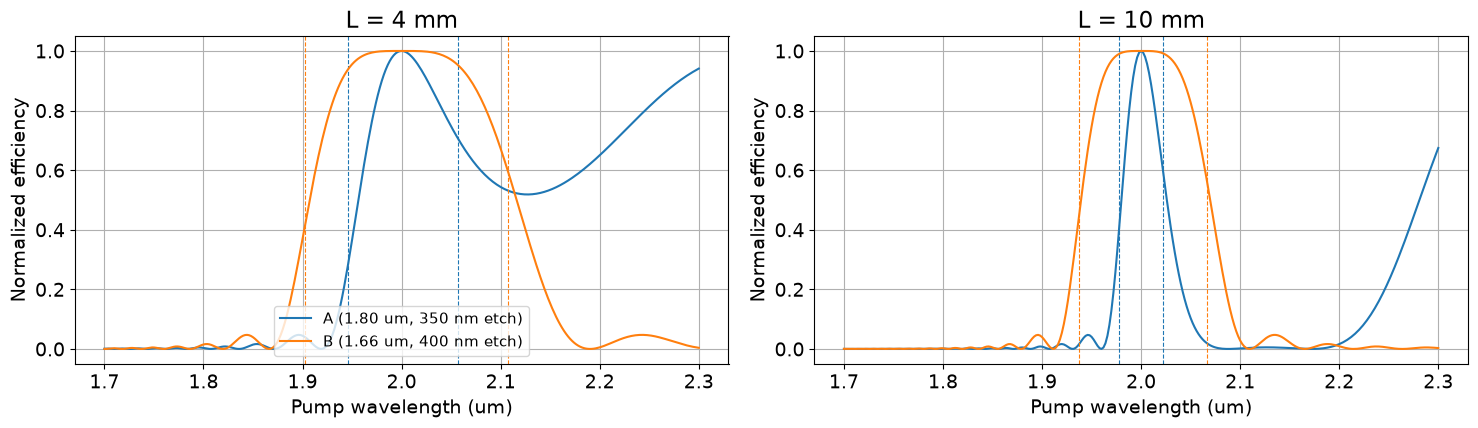

In [3]:
λs = np.linspace(1.7, 2.3, 301)*um
δ = 2*pi*c*(1/λs - 1/λp)   #pump detuning (rad/s)

fig, axes = plt.subplots(1, 2, figsize=(15, 4.5), tight_layout=True)
for ax, L in zip(axes, [4*mm, 10*mm]):
    for (name, wg), color in zip(guides.items(), ['C0', 'C1']):
        Kg = wg.beta(λp/2) - 2*wg.beta(λp)
        Δk = wg.beta(λs/2) - 2*wg.beta(λs) - Kg
        ax.plot(λs/um, np.sinc(Δk*L/(2*pi))**2, color=color, label=name)

        gvm_k = wg.beta1(λp/2) - wg.beta1(λp)
        q = 2*wg.beta2(λp/2) - wg.beta2(λp)
        #half width in δ: the smaller of the GVM and the quadratic estimate
        hw = min(1.39/(abs(gvm_k)*L), np.sqrt(2.78/(abs(q)*L)))
        for s in (-1, 1):
            ax.axvline(1/(1/λp + s*hw/(2*pi*c))/um, color=color, ls='--', lw=0.8)
    ax.set_title('L = %0.0f mm' %(L/mm))
    ax.set_xlabel('Pump wavelength (um)'); ax.set_ylabel('Normalized efficiency')
    ax.grid(True)
axes[0].legend(loc='lower center', fontsize=11);

Going from 4 mm to 10 mm narrows A's curve by 2.5x but B's by only $\sqrt{2.5} \approx 1.6$x. The formulas are Taylor estimates; the solid curves use the full dispersion. A's curve rises again beyond 2.15 µm because its own GVM changes sign there (Tutorial 7 looks at this), and B's is slightly asymmetric because $\beta_3$ is not zero.

## Pulsed SHG

Now the full simulation. A 30 fs sech² pump has a spectral FWHM of 0.315/30 fs = 10.5 THz, wider than A's acceptance at 10 mm. We keep the pump weak (0.1 µW average, 0.4 fJ) so that depletion plays no role and only the dispersion differs between the two devices. Both use the first-order QPM model (`Kg`), so each run takes a fraction of a second.

**Integrator tolerances.** The weak pumps used below give spectra of order 1 in snow's FFT units, while the default absolute tolerance `atol=1e-4` is an absolute error in the same units. With the defaults the integrator takes only a handful of steps over 10 mm and the SH energy is off by up to 0.1 %. We pass `rtol=1e-6, atol=1e-8`, which converges these runs (checked against `rtol=1e-8, atol=1e-12`). Issue #51 tracks making the tolerance relative to the field.

In [4]:
#Bandwidth: pump (2 um) and second harmonic (1 um)
λ_start = 800*nm
λ_stop = 3*um
f_max = c/λ_start
f_min = c/λ_stop
BW = f_max - f_min

N = 2**10       #number of points
Δt = 1/BW       #time resolution
t = (np.arange(N) - N//2)*Δt   #time grid, centred on t = 0
f_ref = (f_max + f_min)/2      #reference frequency

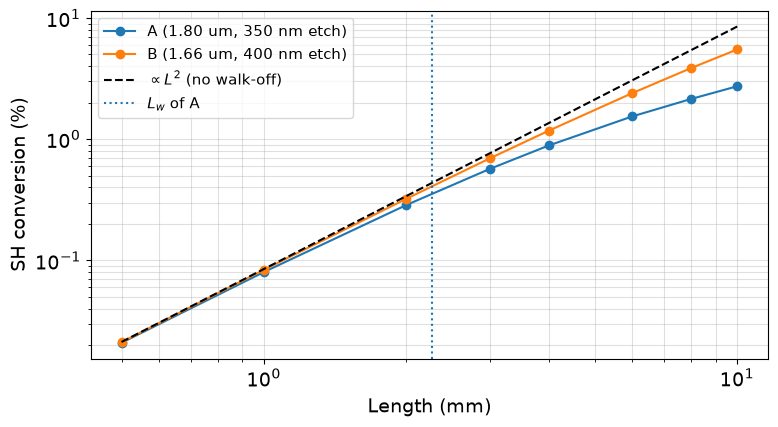

In [5]:
def sh_fraction(out, p_in, λp):
    #Fraction of the input energy above 1.5x the pump frequency
    S = np.abs(out.A)**2
    return S[out.f_abs > 1.5*c/λp].sum()/np.sum(np.abs(p_in.A)**2)

τ = 30*fs
frep = 250*MHz
pump = pulses.sech_pulse(t, τ, Pavg=0.1*uW, f_ref=f_ref, f0=c/λp, Npwr_dB=100, frep=frep, rng=1)
tol = dict(rtol=1e-6, atol=1e-8)

def shg(wg, L):
    #Output pulse of waveguide wg cut to length L, phase matched at λp
    wg.set_length(L)
    Kg = wg.beta(λp/2) - 2*wg.beta(λp)
    return wg.propagate(pump, v_ref=1/wg.beta1(λp/2), Kg=Kg, **tol).pulse

Ls = np.array([0.5, 1, 2, 3, 4, 6, 8, 10])*mm
conv = {name: np.array([sh_fraction(shg(wg, L), pump, λp) for L in Ls]) for name, wg in guides.items()}

#undepleted, no-walk-off reference: η L² ∫|a|⁴dt / E (η as in Tutorial 5)
η = (X0*2*pi*c/(λp/2)/(2*pi))**2
ref = η*Ls**2*np.sum(np.abs(pump.a)**4)*pump.dt/pump.energy_td()

fig, ax = plt.subplots(figsize=(8, 4.5), tight_layout=True)
for name in guides:
    ax.loglog(Ls/mm, 100*conv[name], 'o-', label=name)
ax.loglog(Ls/mm, 100*ref, 'k--', label='$\\propto L^2$ (no walk-off)')
ax.axvline(τ/abs(gvm(1800*nm, 350*nm))/mm, color='C0', ls=':', label='$L_w$ of A')
ax.set_xlabel('Length (mm)'); ax.set_ylabel('SH conversion (%)')
ax.legend(fontsize=11); ax.grid(True, which='both', alpha=0.4)

B follows the $L^2$ law much further. A falls behind once the device is longer than its walk-off length, $L_w = \tau/|\Delta\beta_1| \approx 2.3$ mm, and its conversion then grows only about linearly with $L$. At 10 mm, B converts twice as much energy.

## Spectra and pulses at 10 mm

We isolate the SH with `apply_filter` and compare its spectrum and its pulse.

A (1.80 um, 350 nm etch): SH FWHM 82 fs, transform limit 54 fs
B (1.66 um, 400 nm etch): SH FWHM 49 fs, transform limit 38 fs


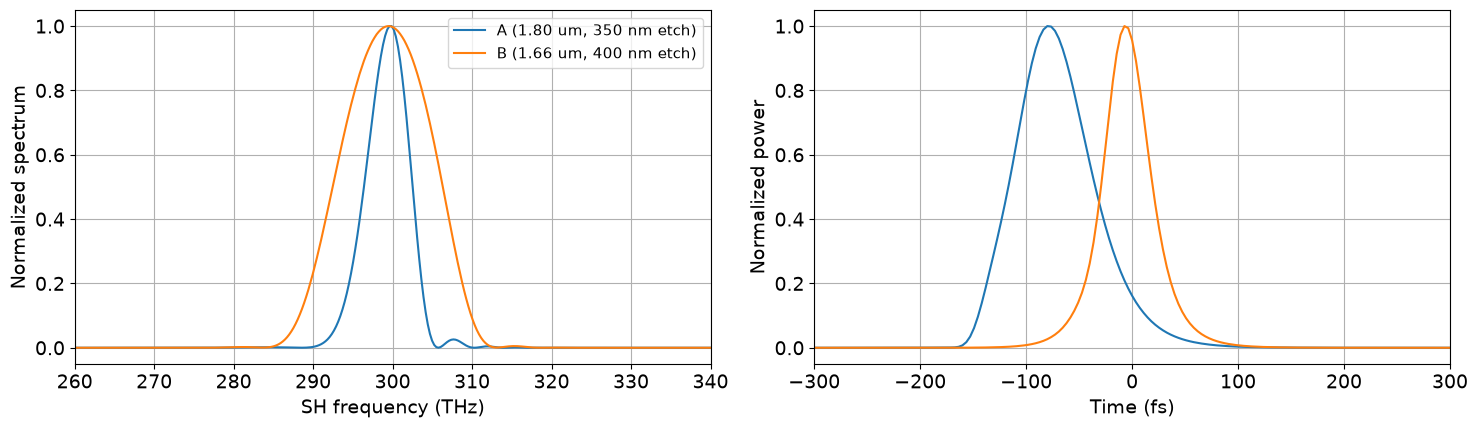

In [6]:
L = 10*mm
f_p = c/λp
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 4.5), tight_layout=True)
for (name, wg), color in zip(guides.items(), ['C0', 'C1']):
    sh = shg(wg, L).apply_filter(2*f_p, f_p)
    S = fftshift(np.abs(sh.A)**2)
    fa = fftshift(sh.f_abs)
    ax1.plot(fa/THz, S/S.max(), color=color, label=name)

    #transform-limited SH: the same spectrum with a flat phase
    tl = pulses.Pulse(t, np.abs(sh.A), sh.wl0, frep, domain='Freq')
    ax2.plot(t/fs, np.abs(sh.a)**2/np.amax(np.abs(sh.a)**2), color=color, label=name)
    print('%s: SH FWHM %0.0f fs, transform limit %0.0f fs' %(name, sh.width_FWHM()/fs, tl.width_FWHM()/fs))

ax1.set_xlim(260, 340)
ax1.set_xlabel('SH frequency (THz)'); ax1.set_ylabel('Normalized spectrum')
ax2.set_xlim(-300, 300)
ax2.set_xlabel('Time (fs)'); ax2.set_ylabel('Normalized power')
ax1.legend(fontsize=11); ax1.grid(True); ax2.grid(True);

B's SH spectrum is more than twice as wide as A's. In time, A's SH is long because it was generated while the pump walked across it, and it sits about 80 fs ahead of B's, the walk-off accumulated over the device. Neither SH pulse is transform limited (the printed durations). B's SH has a GVD of about 137 fs²/mm, so over 10 mm it picks up a chirp; that chirp is mostly quadratic in phase and could be compressed after the waveguide.

## Summary

- GVM limits the SHG bandwidth to $\Delta\omega \approx 2.78/(|\Delta\beta_1|L)$; the time-domain picture is walk-off over $L_w = \tau/|\Delta\beta_1|$.
- Choosing the geometry for zero GVM removes that limit. The bandwidth is then set by the GVD of the pump and the SH and shrinks only as $1/\sqrt{L}$.
- Long zero-GVM devices give broadband, efficient conversion, but the SH comes out chirped by its own GVD.

Tutorial 8 reaches broad bandwidth differently: by chirping the poling period instead of changing the dispersion.